# 発展演習：Kannoらの著者実装でH₄を計算する
## 正準軌道・Boys局在化・軌道順序とMPS/MPO回路圧縮

既存の本編教材とは独立した任意教材です。**論文のITensors回路最適化コードをそのまま実行して得たデータ**を比較します。
主な比較は、同じH₄分子を異なる軌道で表現したとき、厳密解は同じでも、浅い回路での近似のしやすさがどう変わるかです。

**手順**
1. H₄の5構造と厳密なエネルギー差を確認。
2. 正準／Boys／Boys+順序最適化の軌道とHamiltonianを比較。
3. 著者のDMRG・参照MPO・SVDスイープで生成した回路を確認。
4. 同じ深さでの準備の忠実度・時間発展の誤差を比較。
5. 著者と同じGaussianフィット更新による位相差推定を確認。

**範囲**：理想シミュレーションの発展演習です。IBM実機・Fire Opalは実行していません。
Julia/Pythonの版、DMRGの収束設定、実行バックエンドには明記した差があります。
「全く同じ」の範囲は `UPSTREAM.md` を参照してください。

In [1]:
import sys, subprocess, importlib.util
from pathlib import Path
try:
    IS_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IS_COLAB = False
if IS_COLAB:
    subprocess.run([sys.executable,"-m","pip","install","-q","qiskit==2.4.1"],check=True)
    checkout=Path("/content/IBM_handson")
    if not checkout.exists():
        subprocess.run(["git","clone","https://github.com/QS-laboratory/IBM_handson.git",str(checkout)],check=True)
    EXERCISE_ROOT=checkout/"advanced_kanno_h4"
else:
    candidates=[Path.cwd(),Path.cwd()/"advanced_kanno_h4",Path.cwd().parent]
    EXERCISE_ROOT=next(p for p in candidates if (p/"src/author_analysis.py").exists())
if not EXERCISE_ROOT.exists():
    raise FileNotFoundError("発展演習フォルダをGitHubへ配置してからColabで開いてください")
sys.path.insert(0,str(EXERCISE_ROOT/"src"))
import json
import numpy as np
import matplotlib.pyplot as plt
from author_analysis import *
print("Exercise:",EXERCISE_ROOT)
print("No IBM jobs will be submitted.")

Exercise: /Users/sato/project/FTQC_HandsOn/advanced_kanno_h4
No IBM jobs will be submitted.


## 1. 補足資料のH₄構造を確認する

直鎖の隣接H–H距離は2 Å、正方形の一辺は2 Åです。その間を座標の線形補間でつなぎます。
図の線は配置の目安で、Hamiltonianの相互作用をその線上だけに制限するものではありません。
構造は補足Fig. S6から復元しました。元XYZファイルは著者リポジトリにはありませんが、5構造の厳密ギャップは表S1の掲載値と丸め精度で一致します。

基底はSTO-3G、4電子4空間軌道、通常のJordan–Wigner変換で系8量子ビット＋補助1量子ビットです。
ポリエンのπ活性空間と異なり、この模型ではHの4軌道を全て使います。

0 computed gap 0.0159049579 SI table 0.0159
1 computed gap 0.0792608796 SI table 0.0793
2 computed gap 0.1283126248 SI table 0.1283
3 computed gap 0.0769390007 SI table 0.0769
4 computed gap 0.0171308362 SI table 0.0171


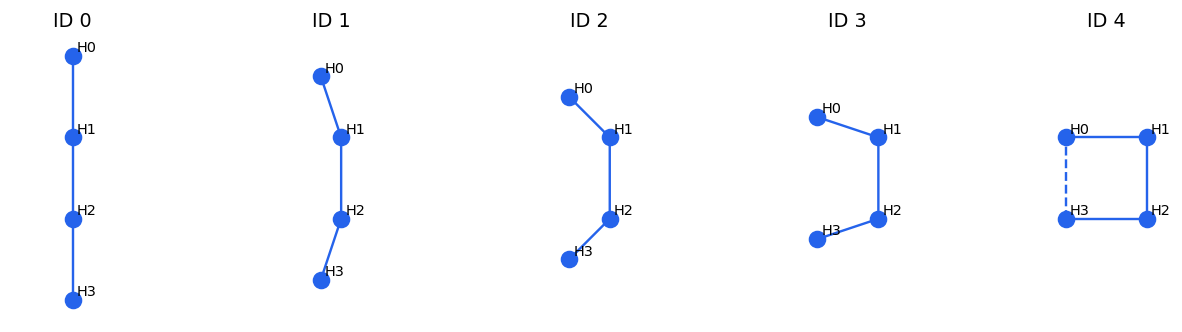

In [2]:
published_gaps=[.0159,.0793,.1283,.0769,.0171]
fig,axes=plt.subplots(1,5,figsize=(12,3))
for geometry,ax in enumerate(axes):
    meta=load_meta("canonical",geometry)
    xyz=np.array(meta["coordinates_angstrom"])
    ax.plot(xyz[:,0],xyz[:,1],"o-",color="#2563eb",markersize=10)
    if geometry==4:ax.plot(xyz[[3,0],0],xyz[[3,0],1],"--",color="#2563eb")
    for atom,(x,y,z) in enumerate(xyz):ax.text(x+.1,y+.1,f"H{atom}",fontsize=9)
    ax.set(xlim=(-1.5,1.5),ylim=(-3.5,3.5))
    ax.set_aspect("equal");ax.set_title(f"ID {geometry}");ax.axis("off")
    print(geometry,"computed gap",round(meta["gap_exact_hartree"],10),"SI table",published_gaps[geometry])
    assert abs(meta["gap_exact_hartree"]-published_gaps[geometry])<.00005
plt.tight_layout();plt.show()

## 2. 軌道を変えても、同じ物理を計算しているか

比較する3種類は次のとおりです。
- **canonical**：RHFの正準分子軌道。
- **boys**：同じ4軌道全体をBoys局在化したもの。
- **boys_ordered**：局在化した軌道を、交換積分と並びの距離で定義するコストを小さくするよう並べ替えたもの。

局在化と並べ替えは同じ軌道空間内のユニタリ変換です。積分を全て変換して厳密に解けば、エネルギーは同じです。
状態の展開係数も変わるので、異なる軌道基底のベクトルどうしを、そのまま内積で比較しません。
軌道数・電子数・基底を変えてしまう比較とは区別します。

下の係数は非直交AO基底での展開係数です。絶対値の2乗をそのまま電子の存在確率と解釈しません。

canonical S0 -3.044331269649873 T1 -3.0284263117336874 gap 0.015904957916185847 Pauli terms 185 exchange cost 2.6342261344316023
boys S0 -3.044331269649874 T1 -3.0284263117336874 gap 0.015904957916186735 Pauli terms 357 exchange cost 0.024724599860042676
boys_ordered S0 -3.044331269649875 T1 -3.028426311733688 gap 0.01590495791618718 Pauli terms 357 exchange cost 0.004436295062431175
Exact energies are invariant under the orbital changes.


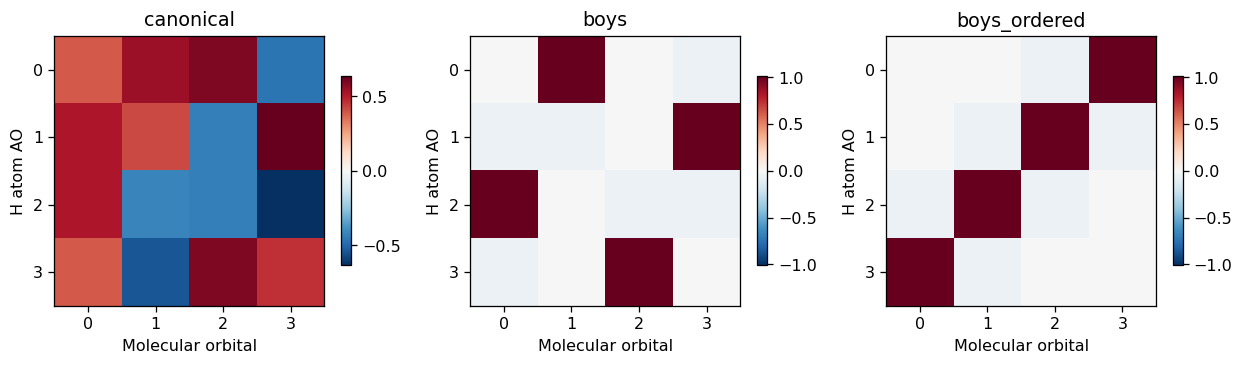

In [3]:
NAMES=["canonical","boys","boys_ordered"]
GEOMETRY=0
fig,axes=plt.subplots(1,3,figsize=(11,3))
for name,ax in zip(NAMES,axes):
    meta=load_meta(name,GEOMETRY);arrays=load_arrays(name,GEOMETRY)
    coeff=arrays["orbital_coefficients"]
    image=ax.imshow(coeff,cmap="RdBu_r",vmin=-np.max(abs(coeff)),vmax=np.max(abs(coeff)))
    ax.set(title=name,xlabel="Molecular orbital",ylabel="H atom AO",xticks=range(4),yticks=range(4))
    print(name,"S0",meta["singlet_electronic_energy_hartree"],"T1",meta["triplet_electronic_energy_hartree"],
          "gap",meta["gap_exact_hartree"],"Pauli terms",meta["pauli_terms"],"exchange cost",meta["exchange_cost"])
    fig.colorbar(image,ax=ax,shrink=.7)
plt.tight_layout();plt.show()
energies=np.array([[load_meta(name,GEOMETRY)[key] for key in ["singlet_electronic_energy_hartree","triplet_electronic_energy_hartree"]] for name in NAMES])
assert np.max(np.ptp(energies,axis=0))<1e-9
print("Exact energies are invariant under the orbital changes.")

### 局在化と順序最適化の評価

著者公開スクリプトと同じDEAPの設定（50個体、100世代、交叉0.7、突然変異0.2）で並べ替えています。
H₄は4軌道なので全24順列も調べ、GAの得たコストが最小値と一致するか確認しています。

コストは公開コードと同じi>jの和で計算しています。論文の全i,jの和とは定数倍の違いがあります。
コストを減らすこと、Pauli項数を減らすこと、浅い回路での近似精度を良くすることは別の指標です。

Best GA cost: 0.004436295062431175
Exhaustive minimum: 0.0044362950624311755


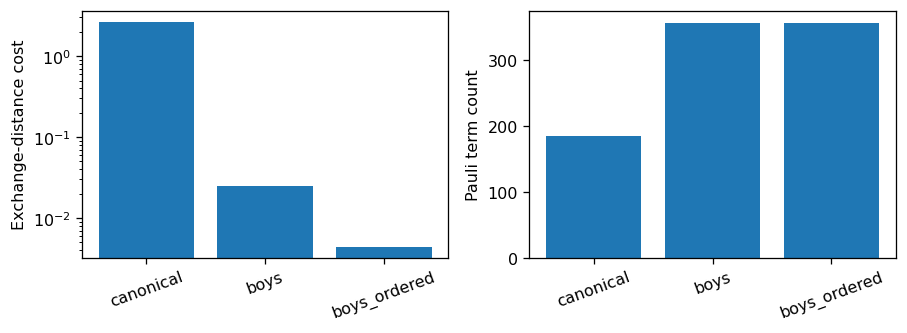

In [4]:
fig,axes=plt.subplots(1,2,figsize=(8,3))
costs=[load_meta(name,GEOMETRY)["exchange_cost"] for name in NAMES]
terms=[load_meta(name,GEOMETRY)["pauli_terms"] for name in NAMES]
axes[0].bar(NAMES,costs);axes[0].set_ylabel("Exchange-distance cost")
axes[0].set_yscale("log")
axes[1].bar(NAMES,terms);axes[1].set_ylabel("Pauli term count")
for ax in axes:ax.tick_params(axis="x",rotation=20)
plt.tight_layout();plt.show()
print("Best GA cost:",load_meta("boys_ordered",GEOMETRY)["exchange_cost"])
print("Exhaustive minimum:",load_meta("boys_ordered",GEOMETRY)["ga_exhaustive_min_cost"])

## 3. 著者実装のMPS/MPOと回路生成

以下は配布済み結果を読むので、参加者はJuliaをインストールする必要がありません。
生成には著者の `Gate_generation_from_MPS_MPO.jl` をバイト同一で使いました。

1. `get_psi_sp`：DMRGの基底状態・第一励起状態から、補助量子ビット付きの重ね合わせMPSを作る。
2. `get_gate_second_trotter`：Δt=0.1を100分割した二次Trotterから参照MPOを作る。
3. `get_and_save_prep_MPSBW_2d_list`：重ね合わせMPSに対する隣接2量子ビットbrick-wall回路を最適化。
4. `get_and_save_evol_BW_2d_list`：参照MPOに対する同形式の回路を最適化。

各ゲートは4×4の一般ユニタリで、環境テンソルの収縮とSVDを用いて順に更新します。
参照MPOはTrotter分割とSVD収縮を含む近似で、厳密な行列指数そのものではありません。密な二次Trotter行列との誤差も別に表示します。
本編のRY/CXの角度フィットやPauli積の時間係数フィットには置き換えていません。
H₄の比較は準備・時間発展とも深さ8、各1000スイープ、seed=1で統一します。

**収束確認**：著者サンプルのDMRG 20スイープは正準H₄で未収束だったため、200へ増やしました。
得たMPSの基底・励起エネルギーが厳密解と一致することを確かめてから回路圧縮へ進めています。

Reference MPO error vs dense Trotter: 0.0002968741514768971
Dense Trotter error vs matrix exponential: 4.4717025710464094e-10
canonical DMRG gap 0.01590495791621338 exact gap 0.015904957916185847 prep overlap 0.9637321109173038 prep fidelity 0.9287795816131224 evolution delta 0.014266056304916456
Reference MPO error vs dense Trotter: 0.0008863482307195944
Dense Trotter error vs matrix exponential: 2.3159569941921357e-10
boys DMRG gap 0.015904974295492202 exact gap 0.015904957916186735 prep overlap 0.9939854937378817 prep fidelity 0.9880071617613404 evolution delta 0.009396121003958776
Reference MPO error vs dense Trotter: 0.0008790084658192069
Dense Trotter error vs matrix exponential: 2.245073063203995e-10
boys_ordered DMRG gap 0.015904974564906027 exact gap 0.01590495791618718 prep overlap 0.9963745803266711 prep fidelity 0.9927623043211501 evolution delta 0.007725966366507103


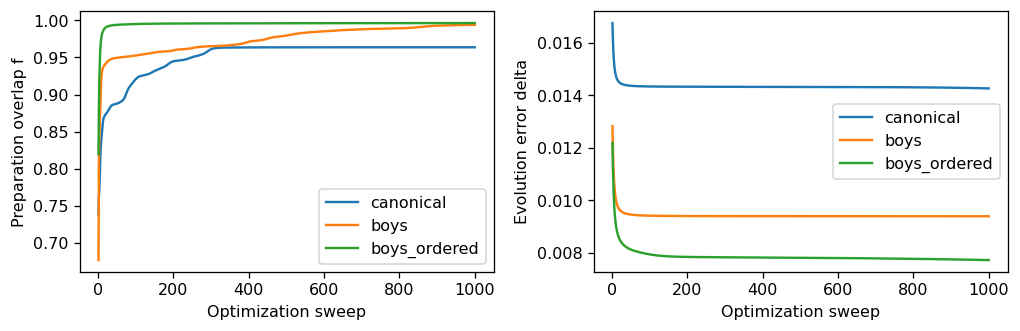

In [5]:
metrics=[json.loads((EXERCISE_ROOT/f"results/geometry_{GEOMETRY}/{name}_metrics.json").read_text()) for name in NAMES]
for row in metrics:
    print("Reference MPO error vs dense Trotter:",row["reference_mpo_vs_dense_trotter_error"])
    print("Dense Trotter error vs matrix exponential:",row["dense_second_trotter_error_vs_exponential"])
    print(row["orbitals"],"DMRG gap",row["dmrg_gap"],"exact gap",row["exact_gap"],
          "prep overlap",row["preparation_overlap"],"prep fidelity",row["preparation_fidelity_squared"],
          "evolution delta",row["evolution_delta_recomputed"])
fig,axes=plt.subplots(1,2,figsize=(9,3))
for name in NAMES:
    folder=EXERCISE_ROOT/f"results/geometry_{GEOMETRY}"
    prep=np.load(folder/f"{name}_prep_history.npy")
    evol=np.load(folder/f"{name}_evol_history.npy")
    axes[0].plot(np.arange(1,len(prep)),prep[1:],label=name)
    axes[1].plot(np.arange(1,len(evol)),evol[1:],label=name)
axes[0].set(xlabel="Optimization sweep",ylabel="Preparation overlap f")
axes[1].set(xlabel="Optimization sweep",ylabel="Evolution error delta")
for ax in axes:ax.legend()
plt.tight_layout();plt.show()

### 同じ深さで何が変わったか

同じbrick-wall構造なら、基本となる2量子ビットブロックの個数は同じです。
参照MPOは目的関数の随伴側として保持されるため、書き出した密行列はU_refの随伴の向きです。
物理的な回路はexp(-i H Δt)と比較し、目的関数Re Tr(U_ref† U_evol)がJulia側の値と一致することを確かめています。
比較するのは、その同じ資源で得られる準備の忠実度と時間発展の近似誤差です。
`f`は目標MPSとの重なりの絶対値、状態の忠実度はその2乗として区別して表示します。
`delta`は論文のN依存の誤差指標で、通常の正規化Frobenius誤差とは別に表示します。

著者のNumPyゲートをQiskitへ読み込んだ結果が、Juliaの最終コストと一致することも数値検証しています。

canonical prep blocks 32 evol blocks 28 prep CX 85 evol CX 84
boys prep blocks 32 evol blocks 28 prep CX 96 evol CX 84
boys_ordered prep blocks 32 evol blocks 28 prep CX 96 evol CX 84
CX counts assume all-to-all connectivity, not an IBM backend ISA.


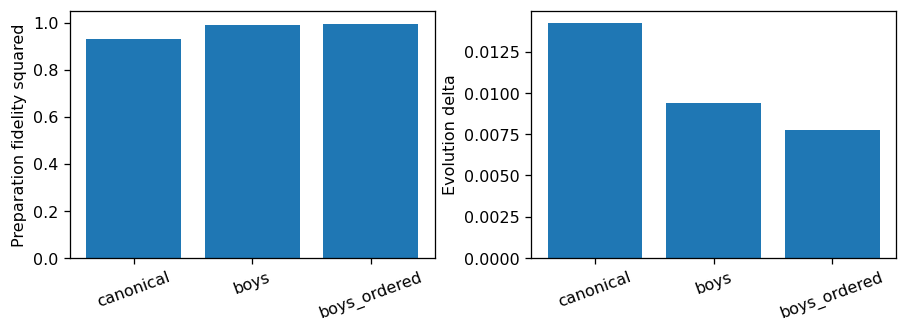

In [6]:
fig,axes=plt.subplots(1,2,figsize=(8,3))
axes[0].bar(NAMES,[m["preparation_fidelity_squared"] for m in metrics])
axes[0].set(ylabel="Preparation fidelity squared",ylim=(0,1.05))
axes[1].bar(NAMES,[m["evolution_delta_recomputed"] for m in metrics])
axes[1].set_ylabel("Evolution delta")
for ax in axes:ax.tick_params(axis="x",rotation=20)
plt.tight_layout();plt.show()
for m in metrics:
    print(m["orbitals"],"prep blocks",m["prep_two_qubit_blocks"],"evol blocks",m["evol_two_qubit_blocks"],
          "prep CX",m["prep_cx_count_all_to_all"],"evol CX",m["evol_cx_count_all_to_all"])
print("CX counts assume all-to-all connectivity, not an IBM backend ISA.")

## 4. 著者と同じ位相差推定・Gaussian更新

補助量子ビットはq0、分子はq1〜q8です。準備→時間発展の反復→補助位相→逆準備→測定、の順で回路を作ります。
初期平均0、初期分散4、探索点21、ショット10,000。各反復では、著者のコードと同じく
`t=1.8/prior_variance`、探索範囲`mean±prior_variance`、実行ステップ数`int(t/0.1)`を使います。
この分散を使った範囲・時間設定は意図的に著者コードに合わせており、標準偏差との取り違えではありません。

観測確率のピークをGaussianでフィットし、その平均・分散と事前Gaussianの積から更新します。
本編の格子上の二項尤度による事後分布とは別の方法です。

配布結果は、同じ回路の理想確率を使った版と、10,000ショットを模擬した版です。IBM実機データではありません。
表示する±標準偏差は、このGaussian更新のパラメータで、全誤差を含む保証ではありません。

canonical status: variance_threshold_reached last estimate: -0.2710822198249216 exact: 0.015904957916185847
  final evolution steps: 264 sum of block CX before routing: 22346
boys status: variance_threshold_reached last estimate: 0.005618558377984142 exact: 0.015904957916186735
  final evolution steps: 261 sum of block CX before routing: 22116
boys_ordered status: variance_threshold_reached last estimate: -0.03961590383785092 exact: 0.01590495791618718
  final evolution steps: 2301 sum of block CX before routing: 193476


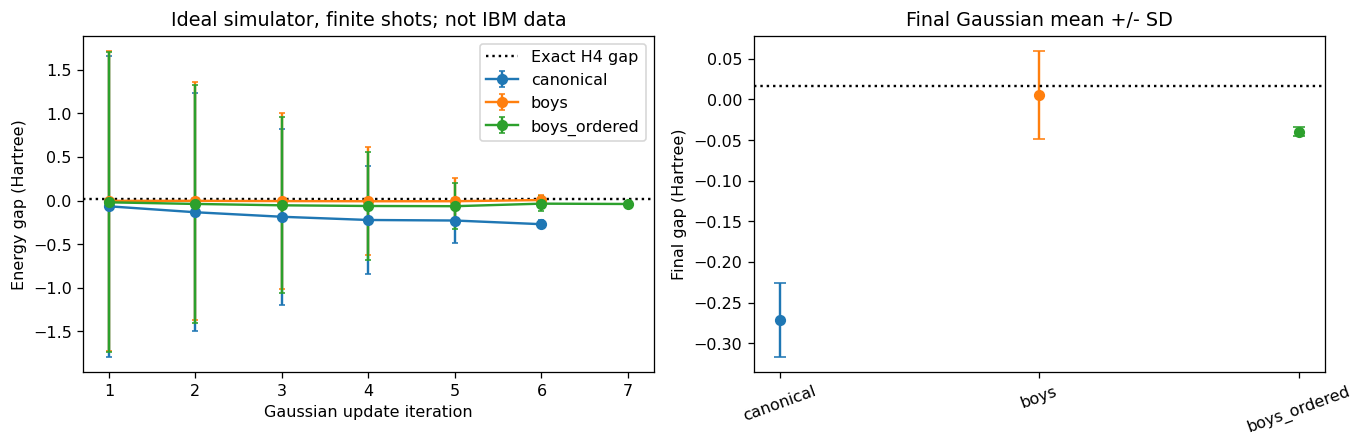

In [7]:
fig,(ax,final_ax)=plt.subplots(1,2,figsize=(12,4))
for index,name in enumerate(NAMES):
    result=json.loads((EXERCISE_ROOT/f"results/geometry_{GEOMETRY}/{name}_qpde_shots.json").read_text())
    rows=[r for r in result["iterations"] if "posterior_mean" in r]
    ax.errorbar([r["iteration"] for r in rows],[r["posterior_mean"] for r in rows],
                yerr=[np.sqrt(r["posterior_variance"]) for r in rows],fmt="o-",capsize=2,label=name)
    print(name,"status:",result["status"],"last estimate:",rows[-1]["posterior_mean"] if rows else None,
          "exact:",result["exact_gap"])
    if rows:
        steps=rows[-1]["steps"]
        cost=next(m for m in metrics if m["orbitals"]==name)
        cx_sum=2*cost["prep_cx_count_all_to_all"]+steps*cost["evol_cx_count_all_to_all"]
        print("  final evolution steps:",steps,"sum of block CX before routing:",cx_sum)
        final_ax.errorbar(index,rows[-1]["posterior_mean"],yerr=np.sqrt(rows[-1]["posterior_variance"]),fmt="o",capsize=4)
final_ax.axhline(load_meta("canonical",GEOMETRY)["gap_exact_hartree"],color="black",ls=":")
final_ax.set(xticks=range(3),xticklabels=NAMES,ylabel="Final gap (Hartree)",title="Final Gaussian mean +/- SD")
final_ax.tick_params(axis="x",rotation=20)
ax.axhline(load_meta("canonical",GEOMETRY)["gap_exact_hartree"],color="black",ls=":",label="Exact H4 gap")
ax.set(xlabel="Gaussian update iteration",ylabel="Energy gap (Hartree)",title="Ideal simulator, finite shots; not IBM data")
ax.legend();plt.tight_layout();plt.show()

### 対照実験：回路近似を取り除く

同じDMRG参照状態と、密な行列指数による厳密な時間発展を使い、推定の更新則だけを同じにした対照です。
ここで厳密ギャップへ近づくかを見ることで、Gaussian更新そのものと回路近似の影響を区別します。
この対照は本手法に置き換えて使うものではなく、誤差の原因を調べる補助実験です。

In [8]:
control=json.loads((EXERCISE_ROOT/f"results/geometry_{GEOMETRY}/canonical_qpde_reference_control_exact.json").read_text())
last=control["iterations"][-1]
print("Reference control (exact probabilities):",last["posterior_mean"])
print("Exact gap:",control["exact_gap"])
print("Absolute difference:",abs(last["posterior_mean"]-control["exact_gap"]))

Reference control (exact probabilities): 0.015905033831640644
Exact gap: 0.015904957916185847
Absolute difference: 7.591545479745943e-08


### 推定の偏りを調べる

推定分散が小さくなっても、厳密ギャップへ近づくとは限りません。
この設定では負の推定値も出ます。符号を反転して正解扱いせず、準備・時間発展の近似や単峰Gaussianモデルを検討する結果として残します。
本論文のH₄表S1にも、理想シミュレーターでの推定値に回路近似由来の偏りが示されています。
長時間では短時間の近似誤差が蓄積し、準備した状態と近似時間発展の固有状態がずれることも影響します。

以下の点を比較してください。
- 正準軌道と局在化軌道で、同じ深さの近似精度はどう違うか。
- 局在化と並べ替えの効果を分けて説明できるか。
- 厳密解が不変なのに推定値が違うのはなぜか。全Fock空間の演算子誤差と、特定2状態のギャップ精度の順位は一致するか。
- 深さを増やす、最適化を増やす、時間を短くする、ショットを増やす、それぞれ何の誤差に効くか。

特定の表現で必ず改善するとは仮定しません。Boys局在化や局所最適化には初期値依存があり、正方形のような高対称構造では特に注意します。

## 出典・再現範囲

- Kanno et al., PNAS 122, e2425026122 (2025)： https://doi.org/10.1073/pnas.2425026122
- 補足資料S1（推定）、S2（圧縮）、S7/Fig. S6/Table S1（H₄）。
- 著者コード： https://github.com/sk888ks/TQPDE_open 、固定コミット `9cd88464c5c50dda783150661813609092d7f2b6`。
- 出所・版・設定変更の詳細：このフォルダの `UPSTREAM.md`。

著者のJuliaコアは未変更ですが、実行環境はJulia 1.11.1 / Python 3.12.7 / Qiskit 2.4.1です。
ITensors 0.6.16、PyCall 1.96.4、Infiltrator 1.7.0は著者と同じ版を固定しています。
同じアルゴリズムをH₄で実行する演習であり、未公開の乱数列・元XYZ・ハードウェア条件・表S1の推定値まで完全同一という主張ではありません。